# Module 2, Lecture 3 — Interpolation

This notebook has two parts:

1. Linear and quadratic interpolation worked out by hand (matrix setup, `np.linalg.solve`), matching the lecture slides exactly.
2. Loads `Module2_FSHD_Dataset.csv`, picking a fair common time point, and working a full example for one subject using both the manual matrix method and `scipy.interpolate.interp1d`.

The last section is your in-class work: apply the same approach to every subject in the dataset and save the results to a new `.csv` file. That part is scaffolded but not solved for you — see the slides and Part 1/2 for the pattern to follow.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


## Part 1: Linear Interpolation — the math

Two known points `(x1, y1)` and `(x2, y2)`. We want the coefficients `a1` (intercept) and `a2` (slope) of `f(x) = a1 + a2*x`, by solving `Y = Z · A`.

In [2]:
# Known points
x1, x2 = 1, 3
y1, y2 = 1, 3

# Z and Y matrices
Z = np.array([[1, x1],
              [1, x2]])
Y = np.array([y1, y2])

# Solve for A = [a1, a2]
A = np.linalg.solve(Z, Y)
print("A =", A)


A = [0. 1.]


In [3]:
# Use the coefficients to estimate y at a new x
a1, a2 = A
x_value = 2
y_value = a1 + a2 * x_value
print(f"At x = {x_value}, y = {y_value}")


At x = 2, y = 2.0


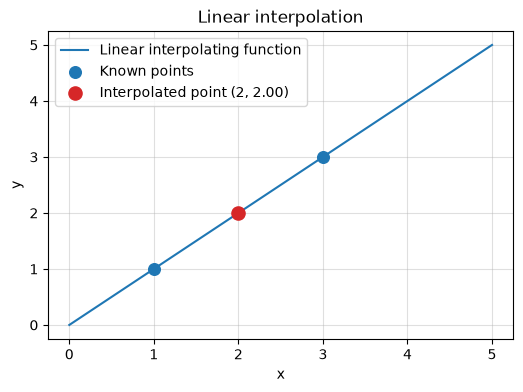

In [4]:
# Plot the line and the interpolated point
x_line = np.linspace(0, 5, 100)
y_line = a1 + a2 * x_line

plt.figure(figsize=(6, 4))
plt.plot(x_line, y_line, label="Linear interpolating function")
plt.scatter([x1, x2], [y1, y2], color="tab:blue", s=70, zorder=4, label="Known points")
plt.scatter([x_value], [y_value], color="tab:red", s=90, zorder=5,
            label=f"Interpolated point ({x_value}, {y_value:.2f})")
plt.title("Linear interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()


## Part 2: Quadratic Interpolation — the math

Three known points. We want `a1, a2, a3` of `f(x) = a1 + a2*x + a3*x²`, again by solving `Y = Z · A` — this time `Z` has three columns: `[1, xi, xi²]`.

In [5]:
# Known points
x1, x2, x3 = 1, 3, 5
y1, y2, y3 = 1, 3, 2

Z = np.array([[1, x1, x1**2],
              [1, x2, x2**2],
              [1, x3, x3**2]])
Y = np.array([y1, y2, y3])

A = np.linalg.solve(Z, Y)
print("A =", A)


A = [-1.125  2.5   -0.375]


In [6]:
a1, a2, a3 = A
x_value = 4
y_value = a1 + a2 * x_value + a3 * x_value**2
print(f"At x = {x_value}, y = {y_value}")


At x = 4, y = 2.875


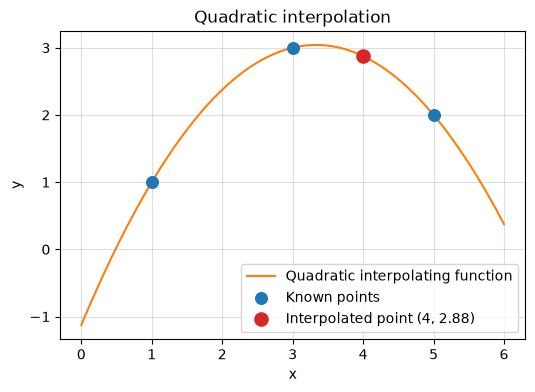

In [7]:
x_curve = np.linspace(0, 6, 200)
y_curve = a1 + a2 * x_curve + a3 * x_curve**2

plt.figure(figsize=(6, 4))
plt.plot(x_curve, y_curve, color="tab:orange", label="Quadratic interpolating function")
plt.scatter([x1, x2, x3], [y1, y2, y3], color="tab:blue", s=70, zorder=4, label="Known points")
plt.scatter([x_value], [y_value], color="tab:red", s=90, zorder=5,
            label=f"Interpolated point ({x_value}, {y_value:.2f})")
plt.title("Quadratic interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()


## Part 3: Loading our data

`Module2_FSHD_Dataset.csv` has one row per subject, with separate columns for each visit (baseline, Year 1, Year 2) rather than one row per visit. Put the CSV in the same folder as this notebook.

In [8]:
df = pd.read_csv("Module2_FSHD_Dataset.csv")
print(df.shape)
df.head()


(34, 46)


,subject_id,sex,age_baseline,d4z4,dux4_signature_baseline_R,dux4_signature_baseline_L,lag_months_baseline,lag_months_y1,lag_months_y2,ff_baseline_R,...,wr_10_y2,ascend_4_baseline,ascend_4_y1,ascend_4_y2,descend_4_baseline,descend_4_y1,descend_4_y2,clinical_severity_score_baseline,clinical_severity_score_y1,clinical_severity_score_y2
0,1-0019,M,47.06,4,0.060426,0.052982,0,11.74,22.78,5.977253,...,2.52,1.89,2.13,1.63,1.76,1.84,1.64,2,3.0,3.0
1,1-0020,F,24.28,4,0.029324,0.085611,0,16.80,NaN,10.825636,...,NaN,2.15,2.50,NaN,1.89,2.07,NaN,4,6.0,NaN
2,1-0021,M,36.42,6,0.056946,0.264634,0,12.20,23.51,3.346368,...,2.65,1.40,1.60,1.76,1.52,1.40,1.39,0,0.0,1.0
3,1-0022,F,59.43,2,0.877067,0.217580,0,13.35,24.82,5.476659,...,4.44,1.97,2.15,1.97,1.87,2.25,2.27,3,3.0,2.0
4,1-0023,M,63.92,5,2.694204,2.876636,0,11.97,24.39,26.596680,...,3.59,2.32,2.26,2.20,2.00,2.13,2.15,4,4.0,6.0


In [9]:
# Check for missing visits -- not every subject has a Year 1 and/or Year 2 visit
print("Subjects:", len(df))
print("Have a Year 1 visit:", df['lag_months_y1'].notna().sum())
print("Have a Year 2 visit:", df['lag_months_y2'].notna().sum())


Subjects: 34
Have a Year 1 visit: 32
Have a Year 2 visit: 27


## Part 4: Choosing a fair common time point

If we just picked month 12 and month 24 for everyone, some subjects' visits never reach that far — estimating for them would mean **extrapolating**, not interpolating.

Instead, we use the earliest "last visit" time shared by the whole group — every subject's own data reaches at least that far, so everyone can be purely interpolated, never extrapolated.

In [10]:
T1 = df['lag_months_y1'].min()   # earliest Year-1 visit across all subjects
T2 = df['lag_months_y2'].min()   # earliest Year-2 visit across all subjects
print(f"T1 = {T1:.2f} months")
print(f"T2 = {T2:.2f} months")


T1 = 11.15 months
T2 = 22.13 months


## Part 5: Worked example — Subject 13-0004

Right tibialis anterior fat fraction (`ff_R`) at all three visits. This subject rises steadily (no dip), and their Year 2 visit is far out at ~37 months, so T1 and T2 both fall cleanly *inside* their data — true interpolation.

In [11]:
row = df.loc[df['subject_id'] == '13-0004'].iloc[0]

lag_months = np.array([row['lag_months_baseline'], row['lag_months_y1'], row['lag_months_y2']])
ff_values = np.array([row['ff_baseline_R'], row['ff_y1_R'], row['ff_y2_R']])

print("lag_months:", lag_months)
print("ff_values: ", ff_values)


lag_months: [ 0.   12.26 36.89]
ff_values:  [ 7.52864406 10.97939387 13.2105723 ]


### Linear interpolation at T1, by hand (using baseline and Year 1)

In [12]:
x1, x2 = lag_months[0], lag_months[1]
y1, y2 = ff_values[0], ff_values[1]

Z = np.array([[1, x1], [1, x2]])
Y = np.array([y1, y2])
A = np.linalg.solve(Z, Y)
a1, a2 = A

estimate_T1 = a1 + a2 * T1
print(f"Linear estimate at T1 = {T1:.2f} months: {estimate_T1:.2f}%")


Linear estimate at T1 = 11.15 months: 10.67%


### Quadratic interpolation at T2, by hand (using all three visits)

In [13]:
Z = np.array([[1, x, x**2] for x in lag_months])
Y = ff_values
A = np.linalg.solve(Z, Y)
a1, a2, a3 = A

estimate_T2 = a1 + a2 * T2 + a3 * T2**2
print(f"Quadratic estimate at T2 = {T2:.2f} months: {estimate_T2:.2f}%")


Quadratic estimate at T2 = 22.13 months: 12.63%


### Same two estimates, the shortcut way with `interp1d`

In [14]:
f_linear = interp1d(lag_months, ff_values, kind='linear')
f_quadratic = interp1d(lag_months, ff_values, kind='quadratic')

print("f_linear(T1)   =", f_linear(T1))
print("f_quadratic(T2) =", f_quadratic(T2))


f_linear(T1)   = 10.666968723617456
f_quadratic(T2) = 12.62727956965659


### Plot: both known visits and both estimates

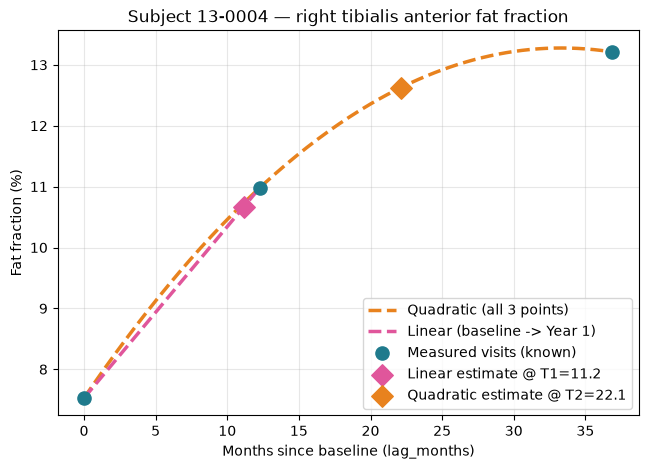

In [15]:
TEAL = "#1f7a8c"
PINK = "#e0569b"
ORANGE = "#e8821e"

x_curve = np.linspace(lag_months[0], lag_months[-1], 200)
quad_curve = f_quadratic(x_curve)

plt.figure(figsize=(7.5, 5))
plt.plot(x_curve, quad_curve, color=ORANGE, lw=2.5, linestyle="--", label="Quadratic (all 3 points)")
plt.plot(lag_months[:2], ff_values[:2], color=PINK, lw=2.5, linestyle="--", label="Linear (baseline -> Year 1)")
plt.scatter(lag_months, ff_values, color=TEAL, s=90, zorder=4, label="Measured visits (known)")
plt.scatter([T1], [estimate_T1], color=PINK, marker="D", s=120, zorder=5, label=f"Linear estimate @ T1={T1:.1f}")
plt.scatter([T2], [estimate_T2], color=ORANGE, marker="D", s=120, zorder=5, label=f"Quadratic estimate @ T2={T2:.1f}")
plt.title("Subject 13-0004 — right tibialis anterior fat fraction")
plt.xlabel("Months since baseline (lag_months)")
plt.ylabel("Fat fraction (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Part 6: Your turn! Apply this to every subject

This is the in-class work / what you should do for your final project analysis. For **every** subject in `df`, using their own `ff_R` measurements:

1. Compute their **linear** estimate at `T1` (needs at least baseline + Year 1).
2. Compute their **quadratic** estimate at `T2` (needs all three visits: baseline, Year 1, Year 2).
3. Some subjects won't have enough data for one or both — decide how you'll record that (e.g. `NaN`) rather than letting the code crash.
4. Save subject ID + both estimates to a new `.csv` file.

The pattern is exactly what you just did above for Subject 13-0004 — now do it inside a loop over `df.iterrows()`. A skeleton is below; it's deliberately incomplete.

In [16]:
results = []

for idx, row in df.iterrows():
    subject_id = row['subject_id']

    # TODO: pull this subject's lag_months and ff_R values into arrays,
    #       the same way we did for Subject 13-0004 above.

    # TODO: if this subject has at least baseline + Year 1 (no NaNs), compute
    #       their linear estimate at T1 (hint: interp1d with kind='linear').
    #       If they don't have enough data, use NaN instead.

    # TODO: if this subject has all three visits (no NaNs), compute their
    #       quadratic estimate at T2 (hint: interp1d with kind='quadratic').
    #       If they don't, use NaN instead.

    # TODO: append a dict like
    #       {'subject_id': subject_id, 'estimate_T1_linear': ..., 'estimate_T2_quadratic': ...}
    #       to `results`
    pass

# TODO: turn `results` into a DataFrame and inspect it
# results_df = pd.DataFrame(results)
# results_df.head()


In [17]:
# TODO: save your results to a new .csv file, e.g.:
# results_df.to_csv('interpolated_estimates.csv', index=False)
